In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal
import numpy as np

In [2]:
df=pd.read_csv('experimento.csv')
df.head()

,t,u,y,uv,yv
0,0.00,1,0.000000,1.000000,0.000000
1,0.01,1,0.033128,1.012566,0.033337
2,0.02,1,0.065849,1.025130,0.066680
3,0.03,1,0.098165,1.037690,0.100026
4,0.04,1,0.130079,1.050244,0.133375


In [5]:
t=df.t
t1=t[1:]
u=df.u
y=df.y
uv=df.uv
yv=df.yv
N_totalu=len(u)
N_totaluv=len(uv)
print (len(uv))
print(len(u))


1001
1001


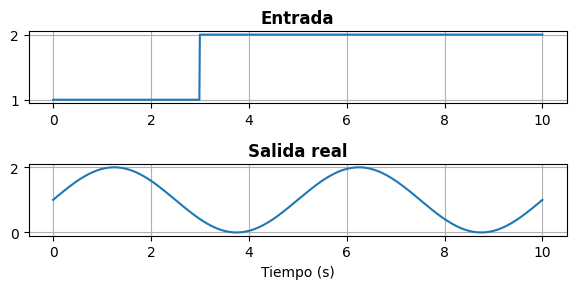

In [124]:
plt.figure(figsize=(6,3))

plt.subplot(2,1,1)
plt.plot(t,u)
plt.grid(True)
plt.title('Entrada',fontweight='bold')

plt.subplot(2,1,2)
plt.plot(t,uv)
plt.grid(True)
plt.title('Salida real',fontweight='bold')
plt.xlabel('Tiempo (s)')

plt.tight_layout()
plt.show()

In [155]:
def identificar_por_desconvolucion(u, y, N):
    pad_length = round(N)
    ypad = np.concatenate([y[:N], np.zeros(pad_length)])
    h, remainder = signal.deconvolve(ypad, u[:N])
    return h


def identificar_por_LSE(t, u, y, N, p):
    T = np.mean(np.diff(t[:N]))
    U = np.zeros((N, p))
    for i in range(p):
        if i == 0:
            U[:, 0] = u[:N]
        else:
            U[i:, i] = u[:N - i]
    U *= T
    A = U.T @ U
    b = U.T @ y[:N]
    h = np.linalg.inv(A)@b*T

    e = y[:N]-U@h

    return h
    

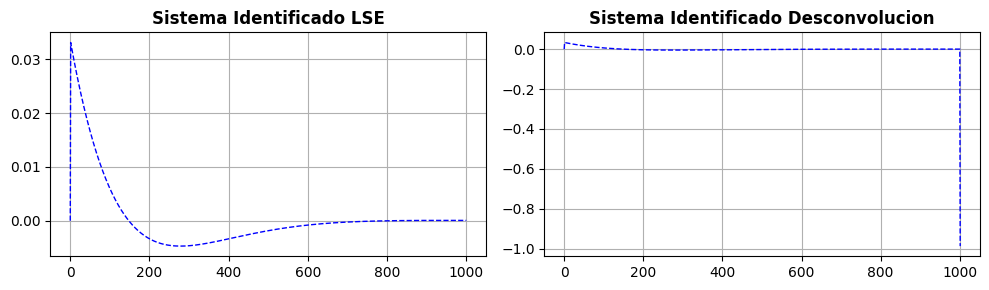

In [156]:
'''Punto 1. Identificando el sistema'''
N = N_totalu
p = round(N) # Me toco el vector completo
h1 = identificar_por_desconvolucion(u, y, N) 
h2 = identificar_por_LSE(t, u, y, N, p)
h3 = identificar_por_desconvolucion(uv, yv, N)
h4 = identificar_por_LSE(t, uv, yv, N, p)

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.plot(h2, label='Real', linewidth=1, linestyle='--',color='blue')
plt.grid() 
plt.title('Sistema Identificado LSE', fontweight='bold') 
plt.tight_layout()

plt.subplot(1, 2, 2)
plt.plot(h1, label='Real', linewidth=1, linestyle='--',color='blue')
plt.grid() 
plt.title('Sistema Identificado Desconvolucion', fontweight='bold') 
plt.tight_layout()
plt.show()


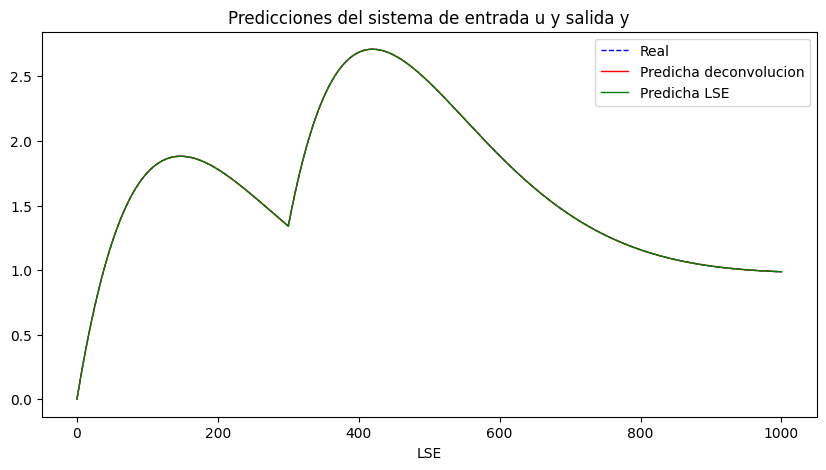

In [157]:
'''Punto 2. Grafica'''
y_real = y[:N]
y_desc = signal.convolve(u[:N], h1)[:N] # desconvolucion
y_lse = signal.convolve(u[:N], h2)[:N] # minimo error

plt.figure(figsize=(10, 5))
plt.title('Predicciones del sistema de entrada u y salida y')
plt.xlabel('Tiempo (s)')
plt.xlabel('LSE')

plt.plot(y_real, label='Real', linewidth=1, linestyle='--',color='blue')
plt.plot(y_desc, label='Predicha deconvolucion', linewidth=1, color='red')
plt.plot(y_lse, label='Predicha LSE', linewidth=1, color='green')
plt.legend()

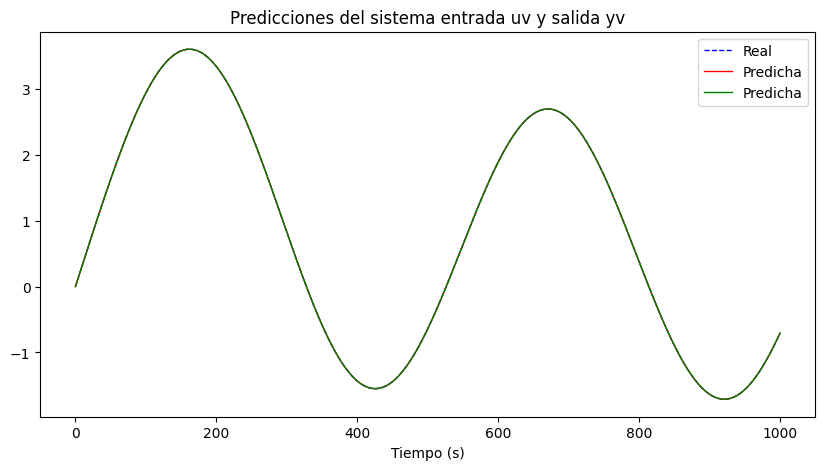

In [158]:
'''punto 3. Entrada u y y yv'''
yv_real = yv[:N]
yv_desc = signal.convolve(uv[:N], h3)[:N] # desconvolucion
yv_lse = signal.convolve(uv[:N], h4)[:N] # minimo error

plt.figure(figsize=(10, 5))
plt.title('Predicciones del sistema entrada uv y salida yv')
plt.xlabel('Tiempo (s)')
plt.plot(yv_real, label='Real', linewidth=1, linestyle='--',color='blue')
plt.plot(yv_desc, label='Predicha', linewidth=1, color='red')
plt.plot(yv_lse, label='Predicha', linewidth=1, color='green')
plt.legend()

In [ ]:
'''Punto 4'''
# Punto a
'''Es necesario mas datos adicionales para que se logre una identificacion mas completa del sistema ya que queda corto para lograr
una aproximacion mas cercana a los datos buscados, entre mas datos mas se acerca al sistema real.'''
# punto b
'''Lo que utilizaria es el PE, un valor de error de predicciones que me indique el numero de erorr utilizado en desconvolucion
y minimo error cuadratico para definir cual tiene menos error.'''